# HOMEWORK 14

In this homework we will be working with the Fashion MNIST dataset. You will be given a classifier which suffers from considerable overfitting. Your objective will be to employ regularization techniques to mitigate the overfitting problem.

Let's start with the usual imports.

In [2]:
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, Input, MaxPooling2D, BatchNormalization, Activation
from tensorflow.keras import Model
from time import time

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

# Set the seeds for reproducibility
from numpy.random import seed
from tensorflow.random import set_seed
seed_value = 1234578790
seed(seed_value)
set_seed(seed_value)

### Dataset

The MNIST fashgion dataset [link](https://github.com/zalandoresearch/fashion-mnist) was build by Zalando Reasearch tem consists of monochrome images of different type of clothing, namely:
* 0	T-shirt/top
* 1	Trouser
* 2	Pullover
* 3	Dress
* 4	Coat
* 5	Sandal
* 6	Shirt
* 7	Sneaker
* 8	Bag
* 9	Ankle boot

It is also one of the Keras built-in datasets. Let's load the images and quickly inspect it.

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Dataset params
num_classes = 10
size = x_train.shape[1]

print('Train set:   ', len(y_train), 'samples')
print('Test set:    ', len(y_test), 'samples')
print('Sample dims: ', x_train.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train set:    60000 samples
Test set:     10000 samples
Sample dims:  (60000, 28, 28)


Let's visualise some random samples.

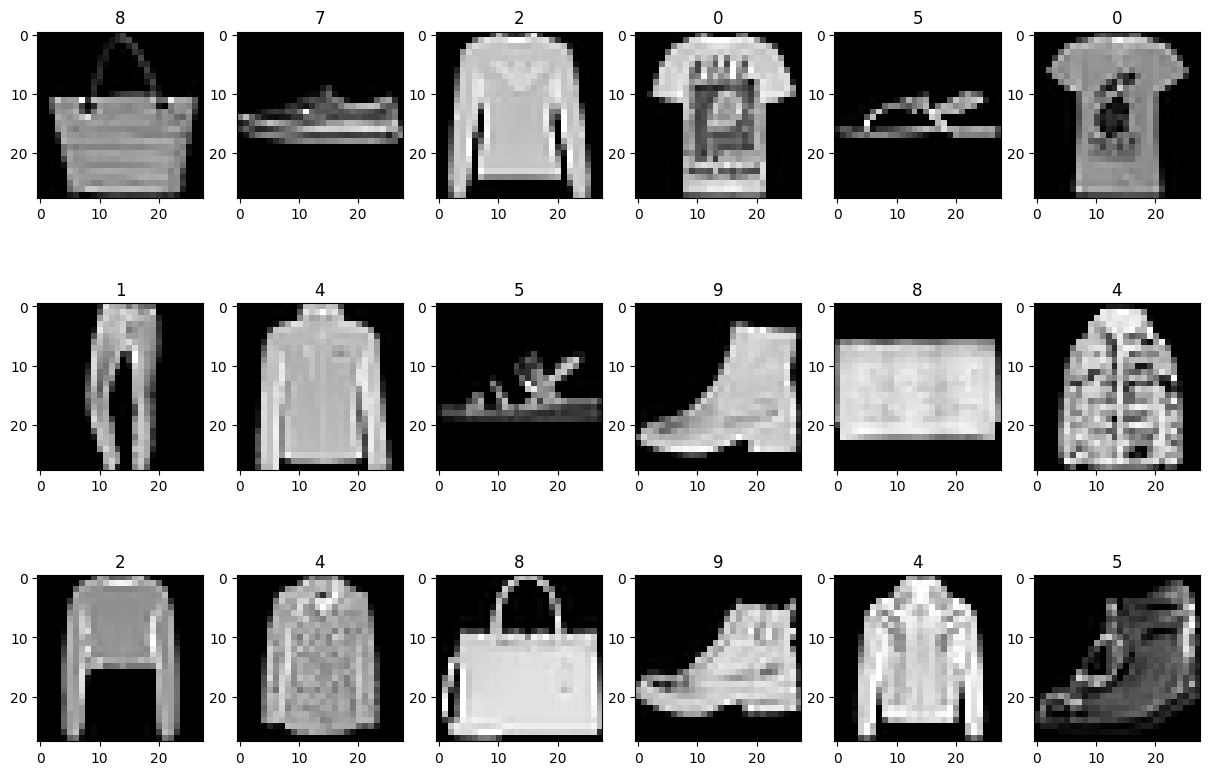

In [4]:
cnt = 1
for r in range(3):
    for c in range(6):
        idx = np.random.randint(len(x_train))
        plt.subplot(3,6,cnt)
        plt.imshow(x_train[idx, ...], cmap='gray')
        plt.title(y_train[idx])
        cnt = cnt + 1

### Building the Classifier

We are now going to build the baseline classifier that you will use throughout this homework.

In [5]:
# Data normalization
x_train = x_train/255
x_test = x_test/255

In [6]:
inputs = Input(shape=(28, 28, 1))
net = Conv2D(32, kernel_size=(3, 3), activation="relu", padding='same')(inputs)
net = Flatten()(net)
net = Dense(128)(net)
outputs = Dense(10, activation="softmax")(net)

model = Model(inputs, outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,213,002 (12.26 MB)

 Trainable params: 3,213,002 (12.26 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
epochs = 50
batch_size = 64

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
history = model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_data=(x_test, y_test))

Epoch 1/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.8671 - loss: 0.3781 - val_accuracy: 0.8863 - val_loss: 0.3200
Epoch 2/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9076 - loss: 0.2579 - val_accuracy: 0.8933 - val_loss: 0.3001
Epoch 3/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9225 - loss: 0.2172 - val_accuracy: 0.8978 - val_loss: 0.2991
Epoch 4/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9324 - loss: 0.1884 - val_accuracy: 0.8965 - val_loss: 0.3135
Epoch 5/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9415 - loss: 0.1650 - val_accuracy: 0.8976 - val_loss: 0.3286
Epoch 6/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9494 - loss: 0.1443 - val_accuracy: 0.8924 - val_loss: 0.3630
Epoch 7/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9564 - loss: 0.1264 - val_accuracy: 0.8941 - val_loss: 0.3881
Epoch 8/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9620 - loss: 0.1108 - val_accuracy: 0

Train Acc      0.9942499995231628
Validation Acc 0.8828999996185303


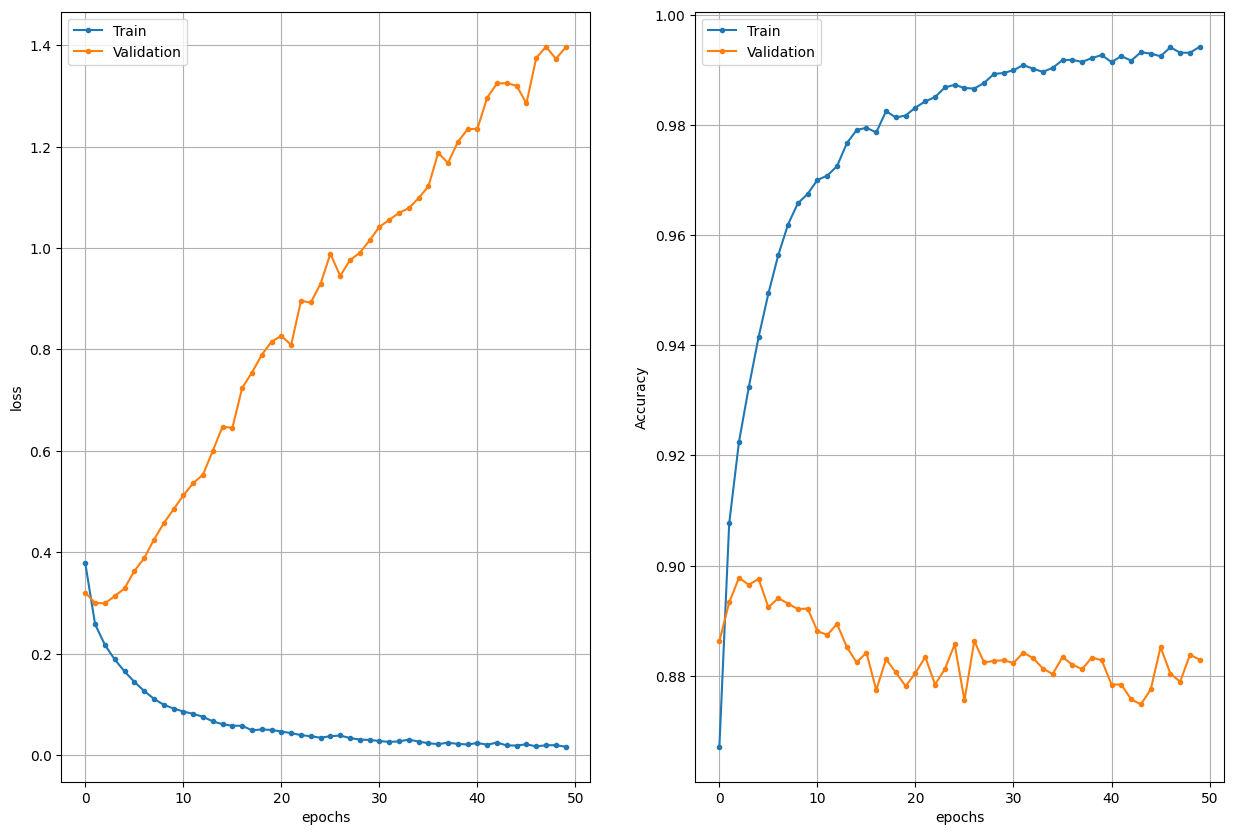

In [8]:
def plot_history(history):
    h = history.history
    epochs = range(len(h['loss']))

    plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
    plt.legend(['Train', 'Validation'])
    plt.subplot(122), plt.plot(epochs, h['accuracy'], '.-',
                               epochs, h['val_accuracy'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('Accuracy')
    plt.legend(['Train', 'Validation'])

    print('Train Acc     ', h['accuracy'][-1])
    print('Validation Acc', h['val_accuracy'][-1])

plot_history(history)

As you can see, the classifier suffers from massive overfitting. The validation accuracy is around 88% while the training accuracy is close to 1.

### Combat the Overfitting!

Now it is your turn. Use the classifier as a baseline, include some regularization techniques and try to improve the classification performance. You can try any techniques you might see fit, e.g.,
* Dropout
* Batch normalization
* Weight regularization
* Data augmentation
* Early stopping
* Pooling
* Reducing the number of parameters (the size of the network)
* ...

There are to objective you shall fulfill in order to successfully complete this homework:
* The validation accuracy shall be above 91%
* Your network (with all the regularizations applied) shall **not** be larger than the baseline

In [9]:
# Modify the baseline classifier in order to reduce the overfitting and make the performance more robust
from tensorflow.keras import regularizers

inputs = Input(shape=(28, 28, 1))
net = Conv2D(32, kernel_size=(3, 3), kernel_regularizer=regularizers.l2(1e-4), padding='same')(inputs)
net = BatchNormalization()(net)
net = Activation('relu')(net)
net = MaxPooling2D(pool_size=(2,2))(net)
net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
net = BatchNormalization()(net)
net = Activation('relu')(net)
net = Flatten()(net)
net = Dense(128, activation="relu")(net)
net = Dropout(0.5)(net)
outputs = Dense(10, activation="softmax")(net)

model = Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 814,058 (3.11 MB)

 Trainable params: 813,930 (3.10 MB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/50
937/937 - 18s - 19ms/step - accuracy: 0.7934 - loss: 0.5885 - val_accuracy: 0.8806 - val_loss: 0.3418
Epoch 2/50
937/937 - 6s - 7ms/step - accuracy: 0.8580 - loss: 0.3986 - val_accuracy: 0.8907 - val_loss: 0.3122
Epoch 3/50
937/937 - 6s - 6ms/step - accuracy: 0.8760 - loss: 0.3493 - val_accuracy: 0.8752 - val_loss: 0.3283
Epoch 4/50
937/937 - 6s - 6ms/step - accuracy: 0.8857 - loss: 0.3161 - val_accuracy: 0.8994 - val_loss: 0.2773
Epoch 5/50
937/937 - 6s - 6ms/step - accuracy: 0.8931 - loss: 0.2986 - val_accuracy: 0.9087 - val_loss: 0.2529
Epoch 6/50
937/937 - 6s - 7ms/step - accuracy: 0.9013 - loss: 0.2761 - val_accuracy: 0.9103 - val_loss: 0.2453
Epoch 7/50
937/937 - 6s - 7ms/step - accuracy: 0.9058 - loss: 0.2627 - val_accuracy: 0.8985 - val_loss: 0.2762
Epoch 8/50
937/937 - 6s - 7ms/step - accuracy: 0.9114 - loss: 0.2454 - val_accuracy: 0.9172 - val_loss: 0.2324
Epoch 9/50
937/937 - 6s - 6ms/step - accuracy: 0.9148 - loss: 0.2361 - val_accuracy: 0.9156 - val_loss: 0.2383

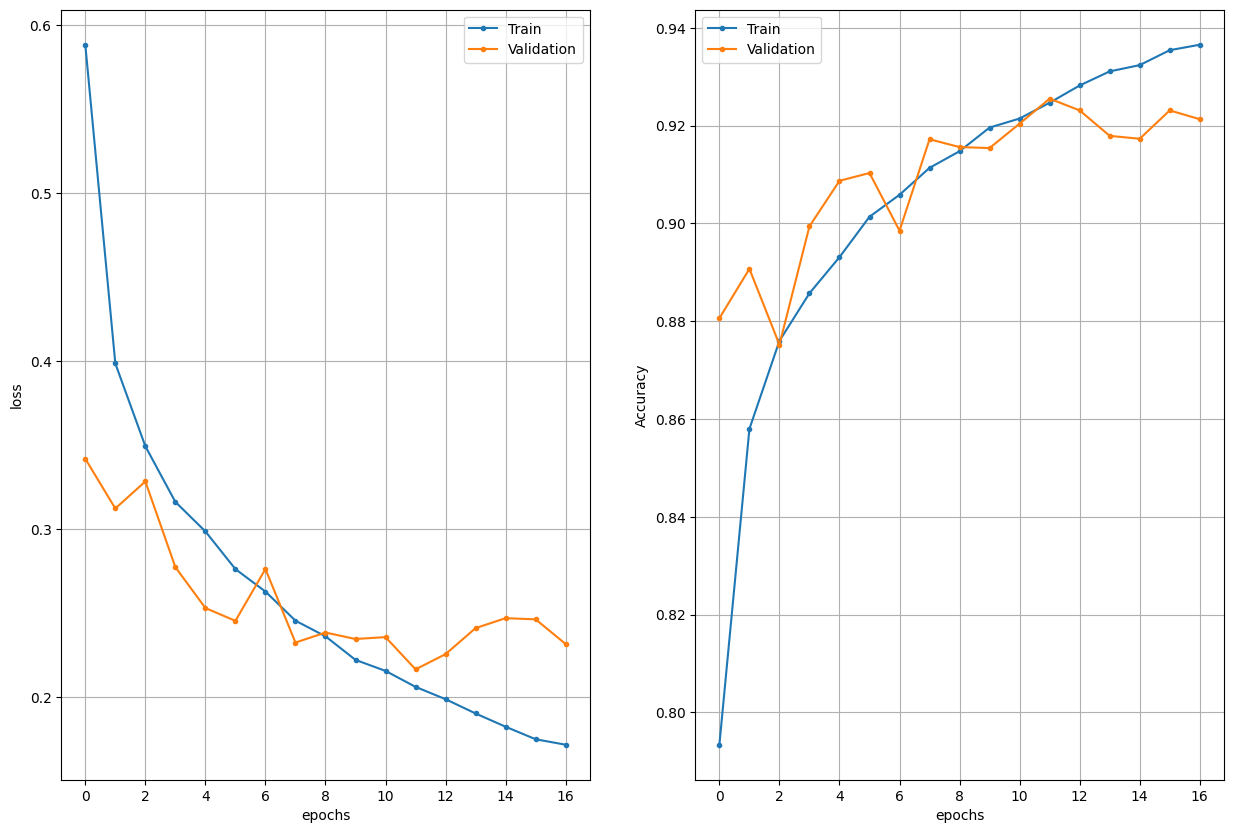

In [10]:
# Train the network
import cv2
from tensorflow import keras
#data augmentation

def datagen(x, y, batch_size):
    num_samples = len(y)
    while True:
        indices = np.random.permutation(num_samples)
        for start in range(0, num_samples - batch_size + 1, batch_size):
            idx = indices[start:start + batch_size]
            x_batch, y_batch = x[idx], y[idx]            # indexing with an array makes a copy, x is not modified

            # Augmentation: mirror a random half of the batch
            flip = np.random.rand(batch_size) > 0.5
            x_batch[flip] = x_batch[flip, :, ::-1]
            #for i in np.where(flip):
               # x_batch[i] = cv2.GaussianBlur(x_batch[i], ksize=(3,3), sigmaX=3)#blur image
            #    angle = np.random.uniform(-15, 15)
            #    h, w = x_batch[i].shape[:2]
            #    center = (w / 2, h / 2)
            #    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
            #    x_batch[i] = cv2.warpAffine(x_batch[i], matrix, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

            yield x_batch, y_batch


steps_per_epoch = len(y_train) // batch_size
generator = datagen(x_train, y_train, batch_size)

checkpoint = keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
earlyStop = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience = 5, restore_best_weights=True)
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
history_flip = model.fit(generator, steps_per_epoch=steps_per_epoch, epochs=epochs, validation_data=(x_test, y_test), callbacks=[checkpoint, earlyStop], shuffle=False, verbose=2)
plot_history(history_flip)

Last epoch | test loss 0.216 | test accuracy 0.925
Best model | test loss 0.216 | test accuracy 0.925


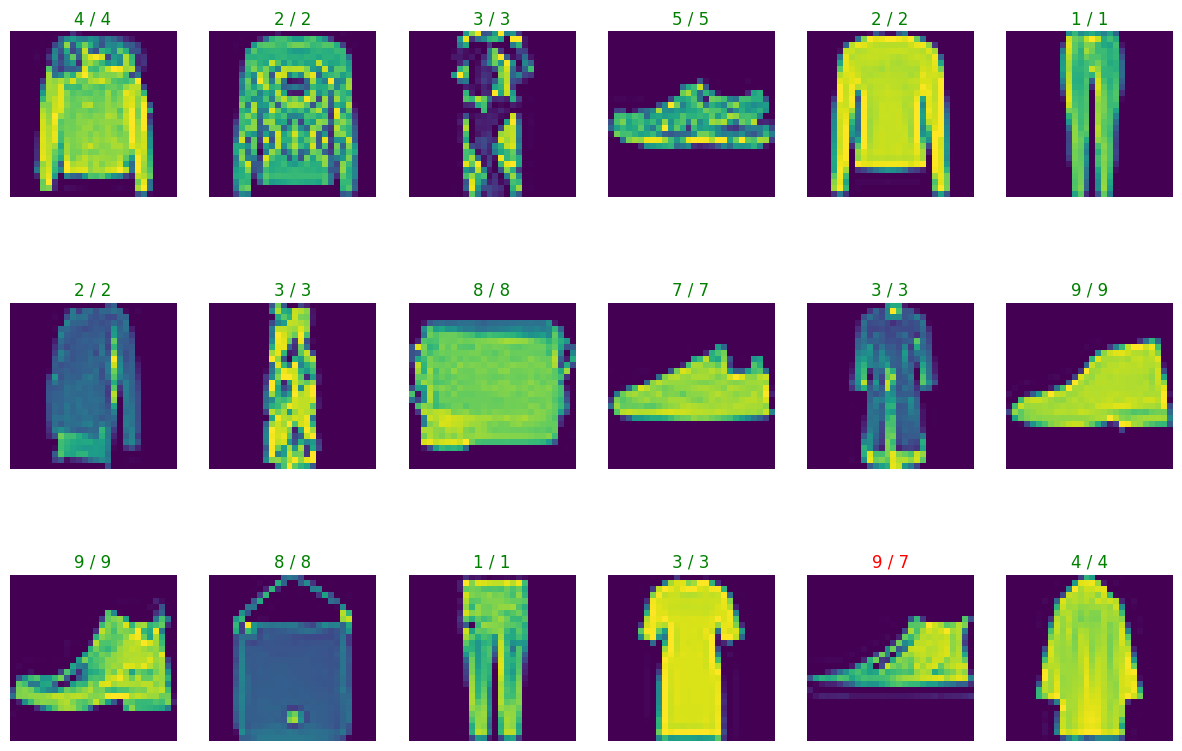

In [11]:
# Show the results
best_model = keras.models.load_model('best_model.keras')

for name, m in [('Last epoch', model), ('Best model', best_model)]:
    loss, acc = m.evaluate(x_test, y_test, verbose=0)
    print(name, '| test loss %.3f | test accuracy %.3f' % (loss, acc))


predictions = best_model.predict(x_test[:1000], verbose=0).argmax(axis=1)

cnt = 1
for r in range(3):
    for c in range(6):
        idx = np.random.randint(1000)
        plt.subplot(3, 6, cnt)
        plt.imshow(x_test[idx, ...])
        plt.title('%s / %s' % (y_test[idx], predictions[idx]),
                  color='green' if predictions[idx] == y_test[idx] else 'red')
        plt.axis('off')
        cnt = cnt + 1

### Questions

* What have you done in order to improve the performance?
1) Data Augmentation (DA) added 0.012 to basic result
2) DA + Batch Normalization (BN) added 0.02 to basic result
3) DA + BN + MaxPooling (MxP) added 0.2 to basic result
4) DA + BN + MxP + Dropout (DO) added 0.2 to basic result
5) DA + BN + MxP + DO + regularization (R) added 0.02 to basic result
6) DA + BN + MxP + DO + R + EarlyStopping maximized the final rezult
7) Finally I added another Convolution layer which added some more trainable parameters but still the network is much smaller than the basic one (814 058 vs 3 213 002 parameters) which gave the best result around 0.925 validation accuracy
* Have you tried configurations that did not work out?
1) Data augmentation via image flip appeared to be most effective (GaussianBlur decreased final result, image rotation -15...15 degrees had not significant effect)
2) Weights regularization in the first Dense layer has decreased final result (Weights regularization 'punishes' too strong parameters, so I guess it should not be used on the last steps)
3) Also I did not mention any change in results with Batch Normalization (perheaps I have used it wrong way)